# 08 · The Supervisor Model

A RAG assistant that nobody checks gets worse silently: documents change, users ask things nobody
anticipated, a threshold that was right in March is wrong in June. Module 07 gave you a **battery** that
you run by hand. This module automates the other half: a **supervisor**, a second model that reads every
answer the assistant gives, decides whether it was good, says *why* when it was not, and feeds the
failures back as fixes to the documentation. That is **continuous improvement** with a human still in
charge.

```
 users ask ─► assistant (retrieve, answer, cite) ─► turn log
                                                     │
                       nightly: supervisor judges every new turn
                                                     │
        ┌────────────────────┬───────────────────────┴──────────────┐
   good answers         retrieval misses                      user remarks
   enter the bank       "what was missing, and where"         judged: documentation | process
   (served without      ─► issue ─► docs agent ─► PR ─► person reviews and merges
    calling the model)                      │
                                  index rebuilt, battery re-run, improvement measured
```

**You will learn**
1. The supervisor's job and its output contract (a verdict, faithfulness, citations, a retrieval diagnosis, what was missing), validated with Pydantic
2. The real judge prompt, and a deterministic stand-in that runs offline
3. A turn log, and the daily evaluation that turns it into a list of retrieval misses
4. The **answer bank**: serving validated answers without a model call, and invalidating them when the documents change
5. User remarks ("request a correction"): judged, then routed to documentation fixes or to the owner
6. Closing the loop on the Harbourview corpus and **measuring** the improvement on questions held out
7. The cautions: the judge can be wrong, calibration against human labels (Cohen's kappa), bias, cost

### Picture: the supervisor and its three outputs

The assistant writes every turn to a log. The **supervisor** reads the log each night and sorts what it finds
into three streams. Only the safe one (good answers) acts on its own; everything that changes the
documentation or a rule passes through a **person**.

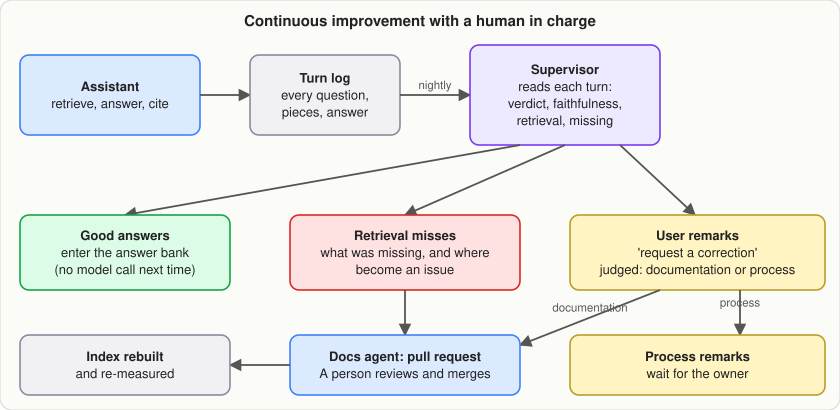

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(840, 410, [
    ("box", 20, 55, 180, 80, "Assistant\nretrieve, answer, cite", "blue"),
    ("arrow", 200, 95, 250, 95, ""),
    ("box", 250, 55, 150, 80, "Turn log\nevery question,\npieces, answer", "grey"),
    ("arrow", 400, 95, 470, 95, "nightly"),
    ("box", 470, 45, 190, 100, "Supervisor\nreads each turn:\nverdict, faithfulness,\nretrieval, missing", "violet"),
    ("arrow", 520, 145, 125, 215, ""),
    ("arrow", 565, 145, 405, 215, ""),
    ("arrow", 620, 145, 695, 215, ""),
    ("box", 20, 215, 210, 75, "Good answers\nenter the answer bank\n(no model call next time)", "green"),
    ("box", 290, 215, 230, 75, "Retrieval misses\nwhat was missing, and where\nbecome an issue", "red"),
    ("box", 570, 215, 255, 75, "User remarks\n'request a correction'\njudged: documentation or process", "gold"),
    ("arrow", 405, 290, 405, 335, ""),
    ("arrow", 660, 290, 520, 345, "documentation"),
    ("arrow", 740, 290, 740, 335, "process"),
    ("box", 290, 335, 230, 60, "Docs agent: pull request\nA person reviews and merges", "blue"),
    ("box", 570, 335, 255, 60, "Process remarks\nwait for the owner", "gold"),
    ("arrow", 290, 365, 230, 365, ""),
    ("box", 20, 335, 210, 60, "Index rebuilt\nand re-measured", "grey"),
], "Continuous improvement with a human in charge")

## 1. The assistant and its documents

The assistant is the one from the previous modules: hybrid retrieval (BM25 and MiniLM embeddings fused by
Reciprocal Rank Fusion, equal weights this time, a realistic untuned setting), three numbered pieces handed
to the answer step, and a quoted, cited answer. The documents now live in a dictionary `DOCS` that can
**change**: the index is rebuilt incrementally when a passage does, re-embedding only that passage.

In [2]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

In [3]:
import re, math, json, time, hashlib, difflib, tempfile, os, textwrap
from collections import Counter
from typing import Literal, Optional
import numpy as np
from pydantic import BaseModel, Field, ValidationError
from sentence_transformers import SentenceTransformer

STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
EMB_CACHE, ENCODED = {}, [0]
def embed(text):
    if text not in EMB_CACHE:
        EMB_CACHE[text] = model.encode(text, normalize_embeddings=True); ENCODED[0] += 1
    return EMB_CACHE[text]

DOCS = {pid: [section, text] for pid, section, text in PASSAGES}      # the documentation, editable

class Index:
    def __init__(self, docs):
        self.ids = list(docs)
        self.docs = {k: list(v) for k, v in docs.items()}
        self.chunks = [f"{docs[i][0]}. {docs[i][1]}" for i in self.ids]
        self.bm25 = BM25(self.chunks)
        self.E = np.stack([embed(c) for c in self.chunks])       # only chunks not seen before are encoded
    def text_hash(self, pid):
        return hashlib.sha1(self.docs[pid][1].encode()).hexdigest()[:10]

def rrf_scores(index, question, weights=(1.0, 1.0), k=60):
    total = np.zeros(len(index.ids))
    for sc, w in zip((index.bm25.scores(question), index.E @ embed(question)), weights):
        for rank, i in enumerate(np.argsort(-sc), start=1):
            total[i] += w / (k + rank)
    return total

def best_sentence(question, text):
    # vocabulary notes ("Also called: ...") help retrieval but are never quoted as the answer
    q = set(tokens(question))
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", text) if not s.startswith("Also called:")]
    return max(sentences, key=lambda s: len(q & set(tokens(s))))

PRICE_IN, PRICE_OUT = 0.20, 0.80      # illustrative USD per million tokens for a small hosted model; check current prices
def assistant(index, question, k=3):
    s_b, s_s = index.bm25.scores(question), index.E @ embed(question)
    order = np.argsort(-rrf_scores(index, question))[:k]
    pieces = [dict(n=n, pid=index.ids[i], section=index.docs[index.ids[i]][0], text=index.docs[index.ids[i]][1]) for n, i in enumerate(order, 1)]
    refused = bool(s_b.max() < 1.0 and s_s.max() < 0.30)
    answer = "I cannot find that in the handbook." if refused else f"{best_sentence(question, pieces[0]['text'])} [1]"
    t_in = int(1.3 * len(" ".join(p["text"] for p in pieces).split()) + 60)       # prompt: instructions + pieces + question
    t_out = int(1.3 * len(answer.split()))
    return dict(question=question, pieces=pieces, answer=answer, refused=refused, model="answer-model-v1",
                tokens_in=t_in, tokens_out=t_out, cost_usd=(t_in * PRICE_IN + t_out * PRICE_OUT) / 1e6)

index = Index(DOCS)
t = assistant(index, "What wave height stops the crew boats from sailing?")
print(t["answer"], "| pieces:", [p["pid"] for p in t["pieces"]], f"| {t['tokens_in']} + {t['tokens_out']} tokens, ${t['cost_usd']:.6f}")

~/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3499.84it/s]

Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [1] | pieces: ['p02', 'p01', 'p09'] | 184 + 32 tokens, $0.000062


## 2. The supervisor's contract

The judge reads **what the assistant saw and said**: the question, the numbered pieces, the answer (and the
result of a data query, if there was one, as in module 06). It returns a small JSON object. The fields are
chosen so that each one drives an action downstream:

| Field | Meaning | Drives |
|---|---|---|
| `verdict` | `correct`, `partial`, `incorrect` or `no_answer` | the day's quality curve |
| `faithfulness` | 1 to 5: is every claim and figure in the pieces? | the answer bank, hallucination alarms |
| `citations_ok` | does each `[n]` exist and support its sentence? | the answer bank |
| `retrieval` | `yes`, `partial`, `no`: did the pieces contain what the question needed? | **where to look**: retrieval or generation |
| `missing` | when retrieval is not `yes`: what was absent and where it should live | the documentation fix |
| `sql_ok` | no query, or a query that answered the question without error | the data path (module 06) |
| `notes` | one sentence of reasoning | the human who audits the judge |

We validate it with **Pydantic**, because the judge is a model and a model's JSON cannot be trusted
blindly: a score of 7, a verdict spelled `mostly ok` or a missing field must be caught at the boundary, not
three steps later.

In [4]:
class JudgeVerdict(BaseModel):
    verdict: Literal["correct", "partial", "incorrect", "no_answer"]
    faithfulness: int = Field(ge=1, le=5)
    citations_ok: bool
    retrieval: Literal["yes", "partial", "no"]
    missing: str = ""
    sql_ok: Optional[bool] = None
    notes: str = ""

good = '{"verdict": "correct", "faithfulness": 5, "citations_ok": true, "retrieval": "yes", "missing": "", "sql_ok": null, "notes": "ok"}'
bad = '{"verdict": "mostly ok", "faithfulness": 7, "citations_ok": "yes", "retrieval": "yes"}'
print("valid  :", JudgeVerdict.model_validate_json(good).verdict)
try:
    JudgeVerdict.model_validate_json(bad)
except ValidationError as e:
    for err in e.errors():
        print("invalid:", err["loc"][0], "->", err["msg"][:70])

valid  : correct
invalid: verdict -> Input should be 'correct', 'partial', 'incorrect' or 'no_answer'
invalid: faithfulness -> Input should be less than or equal to 5


## 3. The real prompt, and a stand-in that runs offline

This is the judge prompt shape used in practice. Notice what it asks for: **rigour** (the judge must not
give the benefit of the doubt), a **closed vocabulary**, and `missing`, which is the field that makes the
whole loop useful.

In [5]:
JUDGE_PROMPT = '''You evaluate the answers of a RAG assistant that answers only from numbered PIECES (and, if present,
a QUERY RESULT cited as [data]). Every sentence of a good answer ends with a citation [n] or [data], and when the
pieces do not contain the answer it says "I cannot find that in the handbook."
Judge strictly:
- verdict: "correct" (answers what was asked and everything is supported), "partial" (answers only part, or lacks
  precision), "incorrect" (states something the pieces contradict or do not support), "no_answer" (says it cannot find it).
- faithfulness: 1 to 5. 5 = every claim and figure is in the pieces, copied exactly.
- citations_ok: true only if every [n] exists and supports its sentence.
- retrieval: "yes" if the pieces had what the question needed, "partial" or "no".
- missing: if retrieval is not "yes", what information was absent and which page or topic should hold it; else "".
- sql_ok: true if there was no query, or the query answered the question without error.
- notes: one sentence with the reason for the verdict.
Reply with ONLY the JSON object {{"verdict": ..., "faithfulness": ..., "citations_ok": ..., "retrieval": ..., "missing": ..., "sql_ok": ..., "notes": ...}}.

PIECES:
{pieces}

QUESTION: {question}

ANSWER: {answer}'''
turn = assistant(index, "What qualification do I need before getting on the boat?")
print(JUDGE_PROMPT.format(pieces="\n".join(f"[{p['n']}] {p['text']}" for p in turn["pieces"]), question=turn["question"], answer=turn["answer"])[-760:])

 "notes": ...}.

PIECES:
[1] New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer.
[2] Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years.
[3] Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later.

QUESTION: What qualification do I need before getting on the boat?

ANSWER: New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer. [1]


In production the judge is a **small, cheap model** (a Haiku-class model, or Amazon Nova Micro or Lite; the
cheapest one that agrees well with your human labels, see section 8) called through the same LiteLLM
interface as module 04. A reasoning-capable judge spends most of its tokens thinking: in the real system this
loop came from, a judge call used about **1,500 tokens of reasoning per answer**, which is why the token
budget of the call must be generous (a limit of 500 returned an empty JSON).

The executed notebook calls **no model**. The stand-in below is a deterministic *rules plus embeddings*
judge. It is deliberately weaker than a language model, and we will measure exactly how much weaker
(section 8). It uses one trick worth noting: for the `retrieval` field it asks a **second opinion** by
ranking the whole corpus with the embedding model alone, and checks whether that passage was among the
pieces the assistant used.

In [6]:
NUM = re.compile(r"\d+(?:\.\d+)?")

def second_opinion(index, question):
    sims = index.E @ embed(question)
    best = int(np.argmax(sims))
    return index.ids[best], float(sims[best])

def stand_in_judge(turn, index):
    pieces, answer, q = turn["pieces"], turn["answer"], turn["question"]
    vocab = {w for c in index.chunks for w in tokens(c)}
    best_pid, best_sim = second_opinion(index, q)
    pids = [p["pid"] for p in pieces]
    if turn["refused"]:
        needed = best_sim >= 0.45            # something clearly relevant exists, so refusing was a retrieval miss
        retrieval = "no" if needed else "yes"
        return dict(verdict="no_answer", faithfulness=5, citations_ok=True, retrieval=retrieval, sql_ok=None,
                    missing=(f"the handbook has material close to the question in '{index.docs[best_pid][0]}'" if needed else ""),
                    notes="unnecessary refusal" if needed else "a correct refusal: nothing relevant in the handbook")
    cites = [int(c) for c in re.findall(r"\[(\d+)\]", answer)]
    body = re.sub(r"\s*\[\d+\]", "", answer)
    valid = bool(cites) and all(1 <= c <= len(pieces) for c in cites)
    cited_text = " ".join(pieces[c - 1]["text"] for c in cites) if valid else ""
    support = len(set(tokens(body)) & set(tokens(cited_text))) / max(len(set(tokens(body))), 1)
    numbers_ok = all(n in NUM.findall(cited_text) for n in NUM.findall(body))
    citations_ok = valid and support >= 0.6
    faith = 5 if citations_ok and numbers_ok else (3 if valid and numbers_ok else (2 if valid else 1))
    retrieval = "yes" if pids[0] == best_pid else ("partial" if best_pid in pids else "no")
    addresses = float(embed(body) @ embed(q)) >= 0.40
    if retrieval == "no":
        verdict = "incorrect"
    elif retrieval == "partial" or not addresses:
        verdict = "partial"
    else:
        verdict = "correct" if citations_ok else "partial"
    missing = ""
    if retrieval != "yes":
        unknown = [w for w in dict.fromkeys(tokens(q)) if w not in vocab]
        missing = (f"the pieces lack the passage '{index.docs[best_pid][0]}' ({best_pid}); words of the question absent from "
                   f"the whole handbook: {', '.join(unknown) or 'none'}")
    return dict(verdict=verdict, faithfulness=faith, citations_ok=citations_ok, retrieval=retrieval, missing=missing, sql_ok=None,
                notes=f"support {support:.0%}, numbers {'ok' if numbers_ok else 'NOT in the cited piece'}, answer-question similarity {'ok' if addresses else 'low'}")

def judge(turn, index, judge_fn=stand_in_judge, retries=1):
    # call the judge, validate its JSON, re-ask once on a malformed reply
    for attempt in range(retries + 1):
        raw = json.dumps(judge_fn(turn, index))
        try:
            return JudgeVerdict.model_validate_json(raw)
        except ValidationError:
            continue
    raise ValueError("the judge never returned a valid verdict")

for q in ["What wave height stops the crew boats from sailing?", "What qualification do I need before getting on the boat?", "Who is the chief executive of the operating company?"]:
    v = judge(assistant(index, q), index)
    print(f"{q[:56]:56s} -> {v.verdict:9s} faith {v.faithfulness} retrieval {v.retrieval:7s} | {v.missing[:70] or v.notes[:70]}")

What wave height stops the crew boats from sailing?      -> correct   faith 5 retrieval yes     | support 100%, numbers ok, answer-question similarity ok
What qualification do I need before getting on the boat? -> partial   faith 5 retrieval partial | the pieces lack the passage 'Safety / Weather limits' (p02); words of 


Who is the chief executive of the operating company?     -> no_answer faith 5 retrieval yes     | a correct refusal: nothing relevant in the handbook


## 4. The turn log and the daily evaluation

Every question the assistant answers is saved as a **turn**: the question, the exact pieces it read (their
text, so the answer can be judged later even if the documents change), the answer, the model, tokens and
cost. This log is the raw material of everything that follows. A nightly job judges the turns not yet
evaluated and writes one **quality record** per turn.

We simulate one day of traffic with the 20 questions of "Day 1" (module 07's set 1, here treated as
anonymous user questions: **the supervisor never sees the reference answers**).

In [7]:
# (id, question, gold passage or None, required fact patterns, forbidden patterns, kind)
SET1 = [
    ("s01", "What wave height stops the crew boats from sailing?", "p02", [r"1\.5 ?m"], [], "direct"),
    ("s02", "How often is the gearbox oil sampled?", "p07", [r"six months"], [], "direct"),
    ("s03", "Who may work alone inside a nacelle?", "p03", [r"forbidden"], [], "paraphrase"),
    ("s04", "What is the rotor diameter of a turbine?", "p04", [r"164 ?m"], [], "direct"),
    ("s05", "What do I do if the pitch fault comes back after a reset?", "p10", [r"replace the hydraulic accumulator"], [], "direct"),
    ("s06", "When must a Level 3 alarm be attended on site?", "p09", [r"24 hours"], [], "direct"),
    ("s07", "How soon must an injury be reported?", "p19", [r"one hour"], [], "direct"),
    ("s08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", [r"300 ?MW"], [r"8\.0 ?MW"], "paraphrase"),
    ("s09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", [r"HV01 to HV08"], [], "paraphrase"),
    ("s10", "How many spare wind vanes are kept in stock?", "p16", [r"four wind vanes"], [], "direct"),
    ("s11", "What qualification do I need before getting on the boat?", "p01", [r"GWO Basic Safety Training"], [], "paraphrase"),
    ("s12", "When can the turbines restart after a blackout?", "p12", [r"10 minutes"], [], "paraphrase"),
    ("s13", "When can a helicopter be used?", "p17", [r"medical evacuation"], [], "direct"),
    ("s14", "What happens when a dolphin is seen near the piling work?", "p13", [r"pause"], [], "paraphrase"),
    ("s15", "What is the price of electricity per MWh?", None, [], [], "trap"),
    ("s16", "Who is the chief executive of the operating company?", None, [], [], "trap"),
    ("s17", "What is the rated power of turbine HV99?", None, [], [], "trap"),
    ("s18", "What availability did the farm achieve last month?", None, [], [], "trap"),
    ("s19", "How many turbines does the farm have?", "p04", [r"40 turbines"], [], "direct"),
    ("s20", "What is the cut-in wind speed?", "p04", [r"3 ?m/s"], [], "direct"),
]
SET2 = [
    ("t01", "Are boats cancelled when the sea is too rough?", "p02", [r"1\.5 ?m"], [], "paraphrase"),
    ("t02", "Can I go up the tower alone to fix something?", "p03", [r"forbidden"], [], "paraphrase"),
    ("t03", "How big are the blades?", "p04", [r"164 ?m"], [], "paraphrase"),
    ("t04", "Who do I call in the middle of the night about an accident?", "p18", [r"control room line"], [], "paraphrase"),
    ("t05", "What if the oil in the gearbox gets dirty?", "p07", [r"filter change"], [], "paraphrase"),
    ("t06", "Do you stop work when whales or seals swim close?", "p13", [r"pause"], [], "paraphrase"),
    ("t07", "How much spare equipment is kept on shore?", "p16", [r"two pitch accumulators"], [], "paraphrase"),
    ("t08", "Is the farm allowed to produce at full output?", "p21", [r"300 ?MW"], [], "paraphrase"),
    ("t09", "What should new colleagues do before their first trip?", "p22", [r"induction"], [], "paraphrase"),
    ("t10", "How should rubbish and old oil be handled?", "p15", [r"brought ashore"], [], "paraphrase"),
    ("t11", "What does code PF-203 mean?", "p10", [r"low accumulator pressure"], [], "identifier"),
    ("t12", "alarm YW-110", "p11", [r"8 degrees"], [], "identifier"),
    ("t13", "ISO 4406 18/16/13", "p07", [r"filter change"], [], "identifier"),
    ("t14", "Where is OSS1?", "p05", [r"centre"], [], "identifier"),
    ("t15", "66 kV cables", "p21", [r"two cables"], [], "identifier"),
    ("t16", "What is the stock price of the operating company?", None, [], [], "trap"),
    ("t17", "What is the rotor diameter of turbine HV77?", None, [], [], "trap"),
    ("t18", "What was the monthly availability in July?", None, [], [], "trap"),
    ("t19", "How many people work on the farm?", None, [], [], "trap"),
    ("t20", "What is the cut-out wind speed?", None if False else "p04", [r"25 ?m/s"], [], "direct"),
]
BATTERY = SET1 + SET2
LOG_DIR = tempfile.mkdtemp(prefix="rag08_")
def append_jsonl(name, record):
    with open(os.path.join(LOG_DIR, name), "a") as f:
        f.write(json.dumps(record) + "\n")

def serve_day(index, battery, day):
    turns = []
    for n, q in enumerate(battery, 1):
        t = assistant(index, q[1])
        t.update(id=f"{day}_{n:02d}", day=day, first_turn=True)
        append_jsonl("chat_turns.jsonl", t)
        turns.append(t)
    return turns

day1 = serve_day(index, SET1, "2026-11-17")
print(len(day1), "turns logged;", f"{sum(t['tokens_in'] + t['tokens_out'] for t in day1)} tokens, ${sum(t['cost_usd'] for t in day1):.5f} for the answers")
print(open(os.path.join(LOG_DIR, "chat_turns.jsonl")).readline()[:230], "...")

20 turns logged; 3709 tokens, $0.00099 for the answers
{"question": "What wave height stops the crew boats from sailing?", "pieces": [{"n": 1, "pid": "p02", "section": "Safety / Weather limits", "text": "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m  ...


In [8]:
def evaluate_day(turns, index):
    records = []
    for t in turns:
        v = judge(t, index)
        rec = dict(turn_id=t["id"], question=t["question"], **v.model_dump())
        append_jsonl("chat_quality.jsonl", rec)
        records.append(rec)
    return records

def summarise(records):
    c = Counter(r["verdict"] for r in records)
    print("verdicts:", dict(c))
    print(f"mean faithfulness {np.mean([r['faithfulness'] for r in records]):.2f}, citations ok {np.mean([r['citations_ok'] for r in records]):.0%}, "
          f"retrieval yes {np.mean([r['retrieval'] == 'yes' for r in records]):.0%}")
    misses = [r for r in records if r["retrieval"] != "yes"]
    print(f"\n{len(misses)} retrieval misses (the input for improving the documentation):")
    for r in misses:
        print(f"  [{r['retrieval']:7s}] {r['question'][:64]}\n            missing: {r['missing'][:150]}")

quality1 = evaluate_day(day1, index)
summarise(quality1)

verdicts: {'correct': 16, 'partial': 2, 'incorrect': 1, 'no_answer': 1}
mean faithfulness 5.00, citations ok 100%, retrieval yes 85%

3 retrieval misses (the input for improving the documentation):
  [partial] What is the largest amount of power the farm is allowed to send 
            missing: the pieces lack the passage 'Grid / Export' (p21); words of the question absent from the whole handbook: largest, amount, farm
  [partial] What qualification do I need before getting on the boat?
            missing: the pieces lack the passage 'Safety / Weather limits' (p02); words of the question absent from the whole handbook: qualification, need, getting, boat
  [no     ] What is the price of electricity per MWh?
            missing: the pieces lack the passage 'Grid / Export' (p21); words of the question absent from the whole handbook: price, electricity, per, mwh


This summary is the point of the whole exercise. It is not "the assistant is 70% good": it is a **work
list**. Each retrieval miss comes with *what was missing*. The qualification question has words that do
not exist anywhere in the handbook (*boat* where the handbook says *vessel*, *qualification* where it says
*certificate*), which suggests the fix is vocabulary, not a new passage and not a new model. The export
question lists only generic words as missing: the judge found the right page but could not name the real
gap (*send ashore* against *export*). The third is a **false alarm** (a question the handbook cannot
answer, which the assistant correctly refused, flagged as a miss): a judge is not always right, which is
why a person still reads this list. A human
reading the raw log would find the same things, once, with effort; the supervisor finds them **every
night**, for every question, for pennies.

## 5. The answer bank

If a question has already been answered **correctly**, answering it again with the model is waste and risk.
The **answer bank** keeps validated answers and serves them back, with no model call, to near-identical
questions. Its admission rule is strict, because the bank is trusted:

* a **first-turn** question (not a follow-up that depends on the conversation),
* verdict `correct`, faithfulness at least 4, citations ok, retrieval `yes`, no failed query.

It stores the **hash of every piece the answer relied on**. When a document changes, the hashes no longer
match and the entry **stops being used**: a validated answer to the old document is not validated for the new
one.

In [9]:
class Bank:
    def __init__(self, threshold):
        self.threshold, self.entries = threshold, []
    def admit(self, turn, rec, index):
        ok = (turn["first_turn"] and rec["verdict"] == "correct" and rec["faithfulness"] >= 4 and rec["citations_ok"]
              and rec["retrieval"] == "yes" and rec["sql_ok"] in (None, True))
        if ok:
            cited = [turn["pieces"][int(n) - 1]["pid"] for n in re.findall(r"\[(\d+)\]", turn["answer"])]
            self.entries.append(dict(question=turn["question"], vec=embed(turn["question"]), answer=turn["answer"],
                                     relied_on={pid: index.text_hash(pid) for pid in cited}, origin="evaluation"))
        return ok
    def lookup(self, question, index):
        if not self.entries:
            return None, 0.0
        sims = [float(e["vec"] @ embed(question)) for e in self.entries]
        i = int(np.argmax(sims))
        e = self.entries[i]
        if sims[i] < self.threshold:
            return None, sims[i]
        if any(pid not in index.docs or index.text_hash(pid) != h for pid, h in e["relied_on"].items()):
            return None, sims[i]            # a piece it relied on has changed: invalidated
        return e, sims[i]

# how close are near-identical questions, and how close are DIFFERENT questions that look similar?
base = "What wave height stops the crew boats from sailing?"
probes = [("same question, one word dropped", "What wave height stops the crew boats sailing?"),
          ("rephrased, same meaning", "What is the wave limit for crew boats?"),
          ("looks similar, different fact (wind, not waves)", "What wind speed stops the crew boats from sailing?"),
          ("different topic", "How often is the gearbox oil sampled?")]
for label, p in probes:
    print(f"cosine {float(embed(base) @ embed(p)):.2f}  {label:50s} {p}")

cosine 1.00  same question, one word dropped                    What wave height stops the crew boats sailing?
cosine 0.83  rephrased, same meaning                            What is the wave limit for crew boats?
cosine 0.78  looks similar, different fact (wind, not waves)    What wind speed stops the crew boats from sailing?
cosine 0.09  different topic                                    How often is the gearbox oil sampled?


This table is how you choose the threshold, and it shows the danger. *"What **wind speed** stops the
boats"* is a **different question** with a different answer (the handbook states both a wave limit and a wind
limit), yet its cosine to the original (0.78) is only a little below that of a true rephrasing (0.83). The
margin between "same meaning" and "looks the same, answers differently" is a few hundredths, so a threshold
chosen to catch rephrasings sits right next to the look-alikes. A strict threshold of **0.95** serves only
near-verbatim repeats, which is the safe default for a bank: it misses some savings and never serves a
wrong answer to a look-alike. Start strict, loosen only with evidence.

In [10]:
bank = Bank(threshold=0.95)
admitted = [bank.admit(t, r, index) for t, r in zip(day1, quality1)]
print(f"{sum(admitted)} of {len(day1)} answers entered the bank (the others failed one of the admission checks)")

for label, p in [("verbatim repeat", base), ("one word dropped", probes[0][1]), ("look-alike (wind speed)", probes[2][1])]:
    e, sim = bank.lookup(p, index)
    print(f"{label:26s} cosine {sim:.2f} -> {'BANK HIT, no model call: ' + e['answer'][:60] if e else 'no hit, the assistant answers'}")

# a document changes: the entry that relied on p02 must stop being used
edited = {k: list(v) for k, v in DOCS.items()}
edited["p02"][1] += " Boats may also be called crew boats."
index_edited = Index(edited)
e, sim = bank.lookup(base, index_edited)
print("after p02 changed ->", "still served (BUG)" if e else "invalidated: the answer is recomputed from the new document")

16 of 20 answers entered the bank (the others failed one of the admission checks)
verbatim repeat            cosine 1.00 -> BANK HIT, no model call: Crew transfer vessels do not sail when the significant wave 
one word dropped           cosine 1.00 -> BANK HIT, no model call: Crew transfer vessels do not sail when the significant wave 
look-alike (wind speed)    cosine 0.78 -> no hit, the assistant answers
after p02 changed -> invalidated: the answer is recomputed from the new document


## 6. User remarks: "request a correction of this answer"

Users see mistakes the judge does not. The interface offers a **request correction** button next to each
answer, and the remark goes to a **second judge** with a different question: *is the remark founded, and if so
what kind of fix does it need?*

* `founded`: `yes`, `partial` or `no`. The documentation is the source of truth **unless the remark shows
  it is wrong or incomplete**, and the judge is told not to agree by default (a polite user can be wrong).
* `kind`: `documentation` (fix or complete a page, or the page is fine but the chat could not find it), `process`
  (the *rule itself* should change: a calculation, a parameter, a procedure) or `none`.

The two kinds travel differently, and this is the safety design:

* a **documentation** remark opens an **issue** that a nightly **docs agent** turns into a **pull request**,
  which **a person reviews and merges**. The agent edits only documentation files, never code, never the
  index, and never merges;
* a **process** remark is a decision about how the business works. It **waits for the owner**, who accepts or
  rejects it. No model changes a safety rule.

In [11]:
UNIT_PAIR = re.compile(r"(\d+(?:\.\d+)?)\s*(hours?|minutes?|months?|MW|kV|m)\b", re.I)
PROCESS_CUE = re.compile(r"\b(change the (rule|procedure|process|limit|calculation)|should depend|new rule|recalculate)\b", re.I)

def judge_remark(turn, comment, index):
    corpus = " ".join(index.docs[p][1] for p in index.ids)
    if PROCESS_CUE.search(comment):
        return dict(founded="partial", kind="process", analysis="The remark asks to change the rule itself; only the owner can decide that.", correction="")
    unsupported = [m for m in UNIT_PAIR.findall(comment) if not re.search(rf"\b{re.escape(m[0])}\s*{m[1]}", corpus, re.I)]
    if unsupported:
        return dict(founded="no", kind="none", analysis=f"The figure {' '.join(unsupported[0])} appears nowhere in the handbook; the documentation says otherwise.", correction="")
    pid, sim = second_opinion(index, turn["question"] + " " + comment)
    return dict(founded="yes", kind="documentation", pid=pid,
                analysis=f"The remark is supported by '{index.docs[pid][0]}' ({pid}), which the assistant did not use.",
                correction=f"Make '{index.docs[pid][0]}' easier to find for questions phrased like: {turn['question']}")

REMARKS = [
    ("What is the largest amount of power the farm is allowed to send ashore?", "The export limit is 300 MW, but you answered with a different topic."),
    ("How soon must an injury be reported?", "The handbook should say 2 hours, not one hour."),
    ("What wave height stops the crew boats from sailing?", "We should change the procedure: the limit should depend on the vessel size."),
]
ISSUES, by_question = [], {t["question"]: t for t in day1}
for question, comment in REMARKS:
    verdict = judge_remark(by_question[question], comment, index)
    print(f"remark: {comment}\n   -> founded={verdict['founded']}, kind={verdict['kind']}: {verdict['analysis']}")
    if verdict["kind"] == "documentation":
        ISSUES.append(dict(label="correccion-docs", pid=verdict["pid"], question=question, comment=comment, correction=verdict["correction"], state="open"))
print()
print("ISSUE OPENED (label correccion-docs):")
print(textwrap.indent(f"Passage: {ISSUES[0]['pid']}\nUser remark: {ISSUES[0]['comment']}\nQuestion: {ISSUES[0]['question']}\nProposed correction: {ISSUES[0]['correction']}", "  "))
print("\nPROCESS remark: status 'to decide', shown to the owner with Accept / Reject. Nothing changes until they choose.")

remark: The export limit is 300 MW, but you answered with a different topic.
   -> founded=yes, kind=documentation: The remark is supported by 'Grid / Export' (p21), which the assistant did not use.
remark: The handbook should say 2 hours, not one hour.
   -> founded=no, kind=none: The figure 2 hours appears nowhere in the handbook; the documentation says otherwise.
remark: We should change the procedure: the limit should depend on the vessel size.
   -> founded=partial, kind=process: The remark asks to change the rule itself; only the owner can decide that.

ISSUE OPENED (label correccion-docs):
  Passage: p21
  User remark: The export limit is 300 MW, but you answered with a different topic.
  Question: What is the largest amount of power the farm is allowed to send ashore?
  Proposed correction: Make 'Grid / Export' easier to find for questions phrased like: What is the largest amount of power the farm is allowed to send ashore?

PROCESS remark: status 'to decide', shown to the owne

## 7. Closing the loop on the Harbourview handbook

Now the whole cycle, with a **measurement**. The ruler is **not** the judge: it is the human-written
reference battery of module 07 (gold passage and required facts), so we are not grading the supervisor with
itself.

1. **Day 1** traffic (set 1) is served and judged. The retrieval misses become issues.
2. The **docs agent** proposes the smallest edit per issue (a line of vocabulary added to the right page) as a
   pull request. It touches documentation only.
3. **A person reviews the PR**. They reject, redirect and complete what the agent proposed. This is the
   human in the loop, and it is what keeps vocabulary edits from turning into noise.
4. On approval the pages change and the **index is rebuilt incrementally**.
5. **Day 2** traffic (set 2, questions *not used* to make the fixes) is served on the old and the new index,
   and we compare.

### Picture: one question, followed through the loop

The notebook's own example: the qualification question. Follow the arrows from the question to the
measurement. The numbers (13/20, 14/20, 10/20, 3 of 22 passages) are the ones printed in this section.

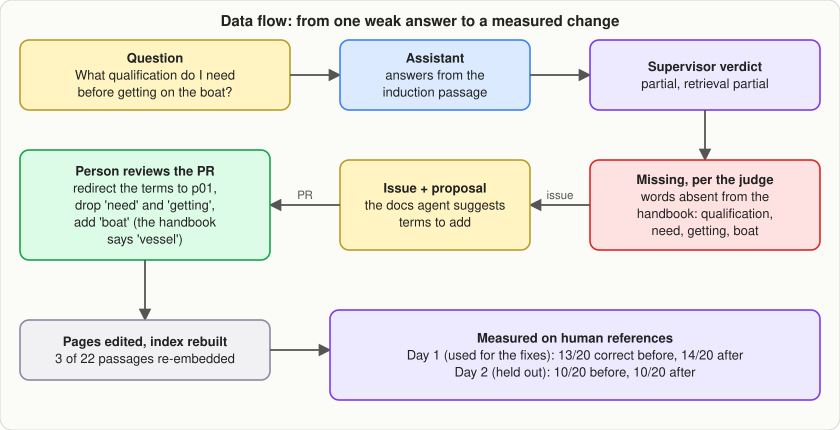

In [12]:
diagram(840, 430, [
    ("box", 20, 40, 270, 70, "Question\nWhat qualification do I need\nbefore getting on the boat?", "gold"),
    ("arrow", 290, 75, 340, 75, ""),
    ("box", 340, 40, 190, 70, "Assistant\nanswers from the\ninduction passage", "blue"),
    ("arrow", 530, 75, 590, 75, ""),
    ("box", 590, 40, 230, 70, "Supervisor verdict\npartial, retrieval partial", "violet"),
    ("arrow", 705, 110, 705, 160, ""),
    ("box", 590, 160, 230, 90, "Missing, per the judge\nwords absent from the\nhandbook: qualification,\nneed, getting, boat", "red"),
    ("arrow", 590, 205, 530, 205, "issue"),
    ("box", 340, 160, 190, 90, "Issue + proposal\nthe docs agent suggests\nterms to add", "gold"),
    ("arrow", 340, 205, 270, 205, "PR"),
    ("box", 20, 150, 250, 110, "Person reviews the PR\nredirect the terms to p01,\ndrop 'need' and 'getting',\nadd 'boat' (the handbook\nsays 'vessel')", "green"),
    ("arrow", 145, 260, 145, 320, ""),
    ("box", 20, 320, 250, 60, "Pages edited, index rebuilt\n3 of 22 passages re-embedded", "grey"),
    ("arrow", 270, 350, 330, 350, ""),
    ("box", 330, 310, 490, 90, "Measured on human references\nDay 1 (used for the fixes): 13/20 correct before, 14/20 after\nDay 2 (held out): 10/20 before, 10/20 after", "violet"),
], "Data flow: from one weak answer to a measured change")

In [13]:
def reference_correct(q, turn):
    qid, question, gold, req, forbid, kind = q
    if gold is None:
        return turn["refused"]
    if turn["refused"]:
        return False
    cited = turn["pieces"][0]["pid"]
    return cited == gold and all(re.search(p, turn["answer"], re.I) for p in req) and not any(re.search(p, turn["answer"], re.I) for p in forbid)

def issues_from_misses(turns, records, index):
    out = []
    for t, r in zip(turns, records):
        if r["retrieval"] == "yes" or not r["missing"]:
            continue
        pid = re.search(r"\((p\d+)\)", r["missing"])
        words = re.search(r"absent from the whole handbook: (.*)$", r["missing"])
        terms = [w.strip() for w in words.group(1).split(",")] if words and words.group(1) != "none" else []
        if pid and terms:
            out.append(dict(pid=pid.group(1), terms=terms, question=t["question"]))
    return out

def docs_agent(issues, docs):
    # nightly agent: the smallest documentation edit per issue, never code, never the index, never merged
    allowed = set(docs)                                  # it can only touch documentation pages
    edits = {}
    for i in issues:
        if i["pid"] in allowed:
            edits.setdefault(i["pid"], []).extend(i["terms"])
    pr = dict(branch="docs/corrections-2026-11-17", status="awaiting human review", changes=[])
    for pid, terms in edits.items():
        terms = list(dict.fromkeys(terms))
        new = docs[pid][1] + f" Also called: {', '.join(terms)}."
        pr["changes"].append(dict(pid=pid, terms=terms, old=docs[pid][1], new=new))
    return pr

misses = issues_from_misses(day1, quality1, index)
pr = docs_agent(misses, DOCS)
print(f"{len(misses)} issues -> pull request '{pr['branch']}' ({pr['status']}), {len(pr['changes'])} pages edited\n")
for ch in pr["changes"]:
    print(f"--- {ch['pid']} ({DOCS[ch['pid']][0]})   proposed terms: {ch['terms']}")

3 issues -> pull request 'docs/corrections-2026-11-17' (awaiting human review), 2 pages edited

--- p21 (Grid / Export)   proposed terms: ['largest', 'amount', 'farm', 'price', 'electricity', 'per', 'mwh']
--- p02 (Safety / Weather limits)   proposed terms: ['qualification', 'need', 'getting', 'boat']


Read the agent's proposal the way the reviewer does, because it is **wrong in three ways**, and that is
normal:

* for `p21` it proposes generic words (*largest*, *amount*, *farm*) plus *price, electricity, per, mwh*,
  which come from a question the handbook **should not** answer: the judge's false alarm leaked into a
  documentation edit. Adding them would make the export passage match electricity-price questions;
* for the qualification question it proposes `p02` (the weather page) because the boat words point there,
  but the page that actually answers it is `p01`, **Safety / Access**, which talks about a *certificate*;
* it cannot know that the handbook says *vessel* everywhere a crew would say *boat*.

A person fixes all three. The review is written down as data so you can see it: every agent change gets a
decision and a reason, and the approved edits are what is applied.

In [14]:
REVIEW_DECISIONS = [
    ("p21 agent terms: largest, amount, farm, price, electricity, per, mwh", "REJECT", "generic words, and 'price/electricity' come from a question that must stay unanswerable (judge false alarm)"),
    ("p21 (user remark about 'send ashore')", "EDIT", "add the user's own words: 'send ashore'"),
    ("p02 agent terms: qualification, need, getting, boat", "REDIRECT", "the question is answered by p01 (Safety / Access, the certificate): move to p01, drop 'need' and 'getting'"),
    ("p02 vocabulary 'boat'", "ADD", "the handbook says 'vessel' on p01 and p02; crews say 'boat'. Note it on both pages (reviewer's domain knowledge)"),
]
APPROVED_EDITS = {"p01": ["qualification", "boat", "boats"], "p02": ["boat", "boats"], "p21": ["send ashore"]}

print(f"{'agent change or proposal':66s}{'decision':>10s}")
for what, decision, why in REVIEW_DECISIONS:
    print(f"{what:66s}{decision:>10s}   {why}")

NEW_DOCS = {k: list(v) for k, v in DOCS.items()}
print()
for pid, terms in APPROVED_EDITS.items():
    NEW_DOCS[pid][1] = DOCS[pid][1] + f" Also called: {', '.join(terms)}."
    diff = [l for l in difflib.unified_diff([DOCS[pid][1]], [NEW_DOCS[pid][1]], lineterm="", n=0) if l.startswith("+") and not l.startswith("+++")]
    print(f"{pid}: ... {diff[0][-60:]}")
before = ENCODED[0]
t0 = time.time()
new_index = Index(NEW_DOCS)
print(f"\nindex rebuilt in {time.time() - t0:.2f} s: {ENCODED[0] - before} of {len(NEW_DOCS)} passages re-embedded (the unchanged ones were reused)")

agent change or proposal                                            decision
p21 agent terms: largest, amount, farm, price, electricity, per, mwh    REJECT   generic words, and 'price/electricity' come from a question that must stay unanswerable (judge false alarm)
p21 (user remark about 'send ashore')                                   EDIT   add the user's own words: 'send ashore'
p02 agent terms: qualification, need, getting, boat                 REDIRECT   the question is answered by p01 (Safety / Access, the certificate): move to p01, drop 'need' and 'getting'
p02 vocabulary 'boat'                                                    ADD   the handbook says 'vessel' on p01 and p02; crews say 'boat'. Note it on both pages (reviewer's domain knowledge)

p01: ... re after two years. Also called: qualification, boat, boats.
p02: ... des at 06:00 and may cancel later. Also called: boat, boats.
p21: ...  with the grid operator is 300 MW. Also called: send ashore.



index rebuilt in 0.15 s: 3 of 22 passages re-embedded (the unchanged ones were reused)


In [15]:
def run_day(idx, battery):
    turns = [assistant(idx, q[1]) for q in battery]
    verdicts = [judge(t, idx) for t in turns]
    ref = [reference_correct(q, t) for q, t in zip(battery, turns)]
    return turns, verdicts, ref

print(f"{'':34s}{'reference correct':>20s}{'judge says correct':>21s}{'retrieval yes':>16s}")
results = {}
for label, battery in [("Day 1 (used to make the fixes)", SET1), ("Day 2 (held out)", SET2)]:
    for name, idx in [("before", index), ("after", new_index)]:
        turns, verdicts, ref = run_day(idx, battery)
        results[(label, name)] = (turns, verdicts, ref)
        print(f"{label:28s}{name:>6s}{sum(ref):>14d} / {len(ref)}{sum(v.verdict == 'correct' for v in verdicts):>16d} / {len(ref)}{sum(v.retrieval == 'yes' for v in verdicts):>11d} / {len(ref)}")

                                     reference correct   judge says correct   retrieval yes
Day 1 (used to make the fixes)before            13 / 20              16 / 20         17 / 20


Day 1 (used to make the fixes) after            14 / 20              18 / 20         19 / 20


Day 2 (held out)            before            10 / 20              11 / 20         13 / 20
Day 2 (held out)             after            10 / 20              11 / 20         13 / 20


Read this table in three steps.

1. **Day 1 before to after** shows the fixes working on the questions that produced them. That is
   necessary but flattering: we wrote the fixes by looking at those very questions.
2. **Day 2** is the test that counts, because none of its questions was used to make a fix. Compare its
   *before* and *after* rows: that is how much of the repair was real vocabulary and how much was
   memorising Day 1.
3. Compare the **reference** column with the **judge** column. The supervisor estimates quality for
   every question without any labels, which is its value, and the gap between its estimate and the
   reference is its error, which is the next section.

Here the honest report is short. On **Day 1** the reference count goes from 13 to 14 correct and retrieval
`yes` from 17 to 19: the qualification question is fixed, and the export-limit question now retrieves the
right passage but still quotes the wrong sentence of it (a generation problem, which no documentation edit
touches). On **Day 2** **nothing moves at all**: 13 of 20 retrieval `yes` and 10 of 20 correct, before and
after. The vocabulary notes fix the words they contain, and Day 2's failures use *other* words (blades,
rubbish, "full output", "in the middle of the night") or are traps. Do not read that as the loop failing.
One night's fixes are narrow by construction, they cost one reviewed pull request, and the battery shows
they caused no regression. Tomorrow's retrieval-miss list, built from Day 2's questions, is the next pull
request. Note also the judge column: it credits 18 of 20 on Day 1 where the reference says 14, the gap
measured in section 8.

## 8. Cautions: the judge is a model too

A supervisor you have not measured is a second source of errors with a confident tone. Four habits keep it
honest.

**1. Calibrate against human labels.** Take a sample of answers, label them yourself, and compare. Raw
accuracy flatters a judge when most answers are correct, so also compute **Cohen's kappa**: agreement
corrected for the agreement you would get by chance (0 is chance, 1 is perfect, above 0.6 is usually
considered substantial). Here the human labels are the reference battery of module 07.

In [16]:
turns_b = results[("Day 1 (used to make the fixes)", "before")][0] + results[("Day 2 (held out)", "before")][0]
verd_b = results[("Day 1 (used to make the fixes)", "before")][1] + results[("Day 2 (held out)", "before")][1]
ref_b = results[("Day 1 (used to make the fixes)", "before")][2] + results[("Day 2 (held out)", "before")][2]
judge_b = [v.verdict == "correct" for v in verd_b]

def cohen_kappa(a, b):
    a, b = np.array(a, dtype=int), np.array(b, dtype=int)
    po = (a == b).mean()
    pe = sum((a == k).mean() * (b == k).mean() for k in (0, 1))
    return (po - pe) / (1 - pe) if pe < 1 else 1.0

tp = sum(j and r for j, r in zip(judge_b, ref_b)); fp = sum(j and not r for j, r in zip(judge_b, ref_b))
fn = sum((not j) and r for j, r in zip(judge_b, ref_b)); tn = sum((not j) and (not r) for j, r in zip(judge_b, ref_b))
print(f"judge vs human reference on {len(ref_b)} answers:  both correct {tp}, both not {tn}, judge too generous {fp}, judge too harsh {fn}")
print(f"agreement {(tp + tn) / len(ref_b):.0%}, Cohen's kappa {cohen_kappa(judge_b, ref_b):.2f}")
print("\nwhere it is too generous (says correct, a human says not):")
for q, t, v, j, r in zip(SET1 + SET2, turns_b, verd_b, judge_b, ref_b):
    if j and not r:
        print(f"  {q[0]} ({q[5]:9s}) {q[1][:60]}")

judge vs human reference on 40 answers:  both correct 20, both not 10, judge too generous 7, judge too harsh 3
agreement 75%, Cohen's kappa 0.47

where it is too generous (says correct, a human says not):
  s05 (direct   ) What do I do if the pitch fault comes back after a reset?
  s12 (paraphrase) When can the turbines restart after a blackout?
  s17 (trap     ) What is the rated power of turbine HV99?
  s18 (trap     ) What availability did the farm achieve last month?
  t05 (paraphrase) What if the oil in the gearbox gets dirty?
  t17 (trap     ) What is the rotor diameter of turbine HV77?
  t18 (trap     ) What was the monthly availability in July?


Read the *too generous* list: those are the supervisor's blind spots, and they are informative. A
rules-and-embeddings stand-in cannot tell that a turbine **HV99** does not exist, or that a stated
**target** is not an achieved value, and it approves answers that quote the wrong sentence of the right
passage, because it sees a relevant passage and approves. A real language
model reads the sentence and catches many of these, but not all, and you only know which by running the
calibration above **with the real judge**, on labels a person wrote. Keep a standing sample of answers that
a human re-labels every week.

**2. Keep a human in the loop where it matters.** Notice what the supervisor was allowed to do in this
module: judge, rank, propose issues. It was **not** allowed to edit the documentation (the agent proposes, a
person merges), change a rule (the owner decides) or promote an answer to the bank without passing the
strict admission test. Autonomy should grow with measured trust, not with enthusiasm.

**3. Do not let a model grade itself.** A judge tends to prefer answers written by its own model family
(*self-preference bias*) and to share its blind spots. Use a **different model** for the judge than for the
answers, and check the judge against humans (habit 1) every time you change either one.

**4. Know what it costs.** The judge reads the question, the pieces and the answer, then reasons. Count it.

In [17]:
JUDGE_IN, JUDGE_OUT = 600, 1500          # tokens per judged answer: prompt plus pieces in, ~1,500 reasoning tokens out
per_answer = (JUDGE_IN * PRICE_IN + JUDGE_OUT * PRICE_OUT) / 1e6
answer_cost = np.mean([t["cost_usd"] for t in day1])
print(f"answering a question:  ${answer_cost:.5f} on average (illustrative small-model prices)")
print(f"judging an answer:     ${per_answer:.5f} ({JUDGE_IN} in + {JUDGE_OUT} out tokens): {per_answer / answer_cost:.0f}x the cost of the answer itself")
for per_day in (50, 200, 1000):
    print(f"{per_day:5d} answers a day: ${per_day * per_answer:6.2f} a day, ${per_day * per_answer * 30:7.2f} a month for judging every one")
print("with the answer bank serving repeats: the model is not called, and the judge is not either")

answering a question:  $0.00005 on average (illustrative small-model prices)
judging an answer:     $0.00132 (600 in + 1500 out tokens): 27x the cost of the answer itself
   50 answers a day: $  0.07 a day, $   1.98 a month for judging every one
  200 answers a day: $  0.26 a day, $   7.92 a month for judging every one
 1000 answers a day: $  1.32 a day, $  39.60 a month for judging every one
with the answer bank serving repeats: the model is not called, and the judge is not either


The judge costs several times the answer, because it *thinks*. That is still cheap per day, and two
levers keep it so: judge a **sample** instead of everything once volume grows, and let the **bank** absorb
repeated questions (a banked answer is neither generated nor re-judged). The prices above are illustrative
placeholders for a small hosted model; take the real ones from your provider's price list.

## 9. Optional: a real judge

Set `RAG_JUDGE_MODEL` to a LiteLLM model name (a Haiku-class model, or Amazon Nova Micro or Lite through
Bedrock; choose one that is **not** the model that writes your answers) and this cell judges the first turn
with the real prompt, validating the reply with the same Pydantic schema. It is **not executed in the
saved notebook**: without the variable it does nothing.

In [18]:
def litellm_judge(turn, index):
    import litellm
    prompt = JUDGE_PROMPT.format(pieces="\n".join(f"[{p['n']}] {p['text']}" for p in turn["pieces"]), question=turn["question"], answer=turn["answer"])
    r = litellm.completion(model=os.environ["RAG_JUDGE_MODEL"], messages=[{"role": "user", "content": prompt}],
                           max_tokens=3000, response_format={"type": "json_object"})     # generous: the judge reasons first
    return json.loads(r.choices[0].message.content)

if os.getenv("RAG_JUDGE_MODEL"):
    print(judge(day1[0], index, judge_fn=litellm_judge).model_dump())
else:
    print("RAG_JUDGE_MODEL is not set: skipped (the notebook uses the deterministic stand-in judge).")

RAG_JUDGE_MODEL is not set: skipped (the notebook uses the deterministic stand-in judge).


## What the real system looked like

A retail supply-chain forecasting assistant ran this loop every working day. Its retrieval was hybrid
(BM25 and embeddings, fused by Reciprocal Rank Fusion), its answer bank was keyed by an embedding
**cosine threshold**, and a judge (a small Claude-class model through a gateway, a different family from the
answering model) read every new answer overnight, writing a verdict, a faithfulness score, whether the
citations held and what retrieval had missed. A judge call used about **1,500 tokens of reasoning**. User
corrections were judged by a second prompt and, when they were documentation fixes, opened issues that a
scheduled agent turned into one pull request per night to a development branch, **never merged by the
agent**. The daily summary of retrieval misses, not the average score, was what the team read.

## Exercises

1. Lower the bank threshold from 0.95 to 0.75 and re-run section 5. Which look-alike question does it
   start serving a wrong answer to? What is the cost of that, compared with the model calls it saves?
2. Day 2 did not move even with `boats` on `p02`. Pick the three Day 2 failures you think a vocabulary
   note could fix, add the words to `APPROVED_EDITS`, and re-run section 7. Day 2 will improve: is that
   the loop generalising, or you memorising Day 2? How would you tell?
3. Write five more remarks of your own for section 6 (one founded, one with a figure that contradicts the
   handbook, one asking for a process change) and check where each is routed.
4. In `stand_in_judge`, make the refusal rule stricter (`best_sim >= 0.35`). How do the number of
   retrieval misses and the kappa of section 8 change?
5. Write down five answers where a *language model* judge would plausibly be wrong. For each, what human
   label would you add to the weekly calibration sample?